# Naive Bayes Classification

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

SEED = 42

## 1. Load the Training and Testing Sets

In [3]:
train = pd.read_csv("train_set.csv")
test = pd.read_csv("test_set.csv")

X_train, y_train = train.drop(columns="Label"), train["Label"]
X_test, y_test = test.drop(columns="Label"), test["Label"]
classes = sorted(y_train.unique())

print(f"Training set: {X_train.shape[0]:,} flows, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]:,} flows")
print(f"Classes:      {len(classes)}")

Training set: 7,508 flows, 65 features
Testing set:  3,218 flows
Classes:      15


## 2. Prepare the Features

Sign preserving log transform followed by min-max scaling to the range 0 to 1.

In [4]:
def signed_log(df):
    return np.sign(df) * np.log1p(df.abs())

scaler = MinMaxScaler().fit(signed_log(X_train))

S_train = scaler.transform(signed_log(X_train))
S_test_raw = scaler.transform(signed_log(X_test))
S_test = np.clip(S_test_raw, 0, 1)

clipped = (S_test_raw != S_test).mean()
print(f"Training values range: {S_train.min():.1f} to {S_train.max():.1f}")
print(f"Share of testing values clipped: {clipped:.3%}")

Training values range: 0.0 to 1.0
Share of testing values clipped: 0.004%


## 3. Baseline

In [5]:
majority = y_train.value_counts().idxmax()
baseline_acc = (y_test == majority).mean()
print(f"Most common training class: {majority}")
print(f"Baseline accuracy on testing set: {baseline_acc:.3f}")

Most common training class: FTP-Patator
Baseline accuracy on testing set: 0.093


## 4. Multinomial Naive Bayes

The smoothing parameter alpha is selected by 5-fold cross-validation on the training set.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
alphas = [0.001, 0.01, 0.1, 1, 10]

cv_scores = {a: cross_val_score(MultinomialNB(alpha=a), S_train, y_train, cv=cv).mean() for a in alphas}
pd.Series(cv_scores, name="CV accuracy").rename_axis("alpha").round(4).to_frame()

,CV accuracy
alpha,
0.001,0.5597
0.010,0.5593
0.100,0.5589
1.000,0.5573
10.000,0.5358


In [7]:
best_alpha = max(cv_scores, key=cv_scores.get)

mnb = MultinomialNB(alpha=best_alpha).fit(S_train, y_train)
pred_mnb = mnb.predict(S_test)

acc_mnb = accuracy_score(y_test, pred_mnb)
print(f"Selected alpha: {best_alpha}")
print(f"Training accuracy: {mnb.score(S_train, y_train):.3f}")
print(f"Testing accuracy:  {acc_mnb:.3f}")

Selected alpha: 0.001
Training accuracy: 0.560
Testing accuracy:  0.564


### Confusion Matrix

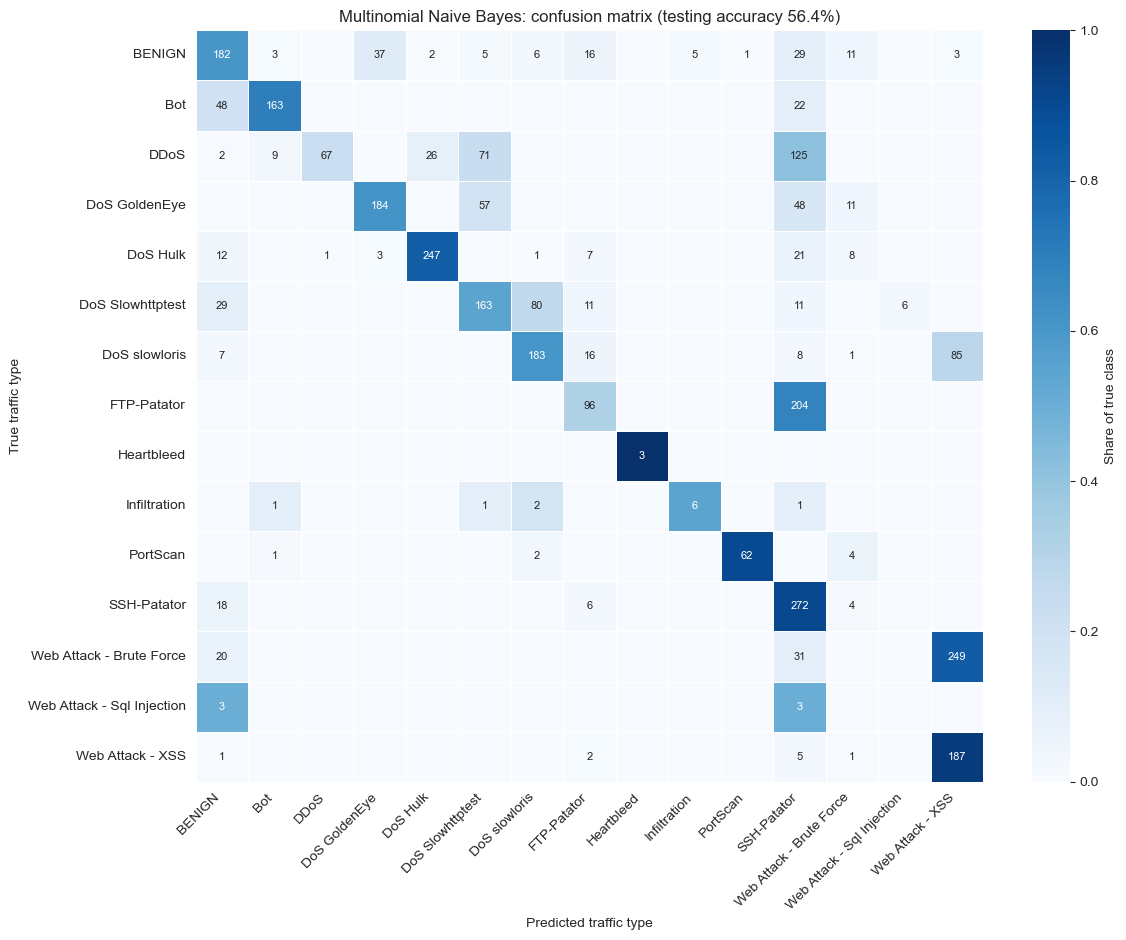

In [8]:
def plot_confusion(y_true, y_pred, title, path):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    share = cm / cm.sum(axis=1, keepdims=True)
    annot = np.where(cm == 0, "", cm.astype(str))

    fig, ax = plt.subplots(figsize=(12, 9.5))
    sns.heatmap(share, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=classes, yticklabels=classes, linewidths=0.4, linecolor="white",
                cbar_kws={"label": "Share of true class"}, annot_kws={"fontsize": 8}, ax=ax)
    ax.set_xlabel("Predicted traffic type")
    ax.set_ylabel("True traffic type")
    ax.set_title(title)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    return cm

cm_mnb = plot_confusion(y_test, pred_mnb,
                        f"Multinomial Naive Bayes: confusion matrix (testing accuracy {acc_mnb:.1%})",
                        "figures/nb-01-confusion-multinomial.png")

### Precision and Recall by Traffic Type

In [9]:
report_mnb = pd.DataFrame(classification_report(y_test, pred_mnb, output_dict=True, zero_division=0)).T
report_mnb = report_mnb.loc[classes + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
report_mnb.round(3)

,precision,recall,f1-score,support
BENIGN,0.565,0.607,0.585,300.0
Bot,0.921,0.700,0.795,233.0
DDoS,0.985,0.223,0.364,300.0
DoS GoldenEye,0.821,0.613,0.702,300.0
DoS Hulk,0.898,0.823,0.859,300.0
DoS Slowhttptest,0.549,0.543,0.546,300.0
DoS slowloris,0.668,0.610,0.638,300.0
FTP-Patator,0.623,0.320,0.423,300.0
Heartbleed,1.000,1.000,1.000,3.0
Infiltration,0.545,0.545,0.545,11.0


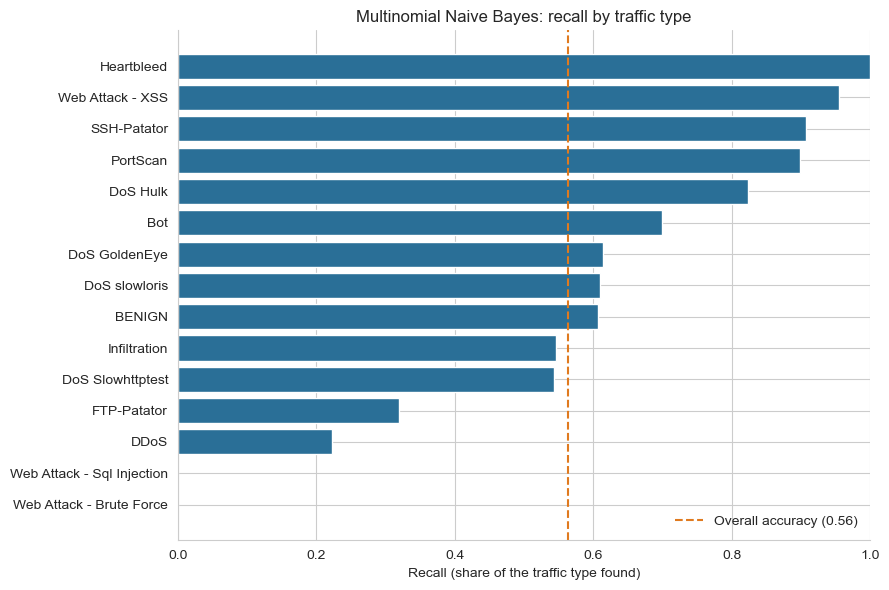

In [10]:
recall = report_mnb.loc[classes, "recall"].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(recall.index, recall.values, color="#2a6f97")
ax.axvline(acc_mnb, color="#e07a1f", linestyle="--", linewidth=1.5, label=f"Overall accuracy ({acc_mnb:.2f})")
ax.set_xlim(0, 1)
ax.set_xlabel("Recall (share of the traffic type found)")
ax.set_title("Multinomial Naive Bayes: recall by traffic type")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("figures/nb-02-recall-by-class.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Bernoulli Naive Bayes

In [11]:
medians = np.median(S_train, axis=0)

B_train = (S_train > medians).astype(int)
B_test = (S_test > medians).astype(int)

cv_scores_b = {a: cross_val_score(BernoulliNB(alpha=a, binarize=None), B_train, y_train, cv=cv).mean()
               for a in alphas}
pd.Series(cv_scores_b, name="CV accuracy").rename_axis("alpha").round(4).to_frame()

,CV accuracy
alpha,
0.001,0.6336
0.010,0.6308
0.100,0.6249
1.000,0.5550
10.000,0.5390


In [12]:
best_alpha_b = max(cv_scores_b, key=cv_scores_b.get)

bnb = BernoulliNB(alpha=best_alpha_b, binarize=None).fit(B_train, y_train)
pred_bnb = bnb.predict(B_test)

acc_bnb = accuracy_score(y_test, pred_bnb)
print(f"Selected alpha: {best_alpha_b}")
print(f"Training accuracy: {bnb.score(B_train, y_train):.3f}")
print(f"Testing accuracy:  {acc_bnb:.3f}")

Selected alpha: 0.001
Training accuracy: 0.631
Testing accuracy:  0.640


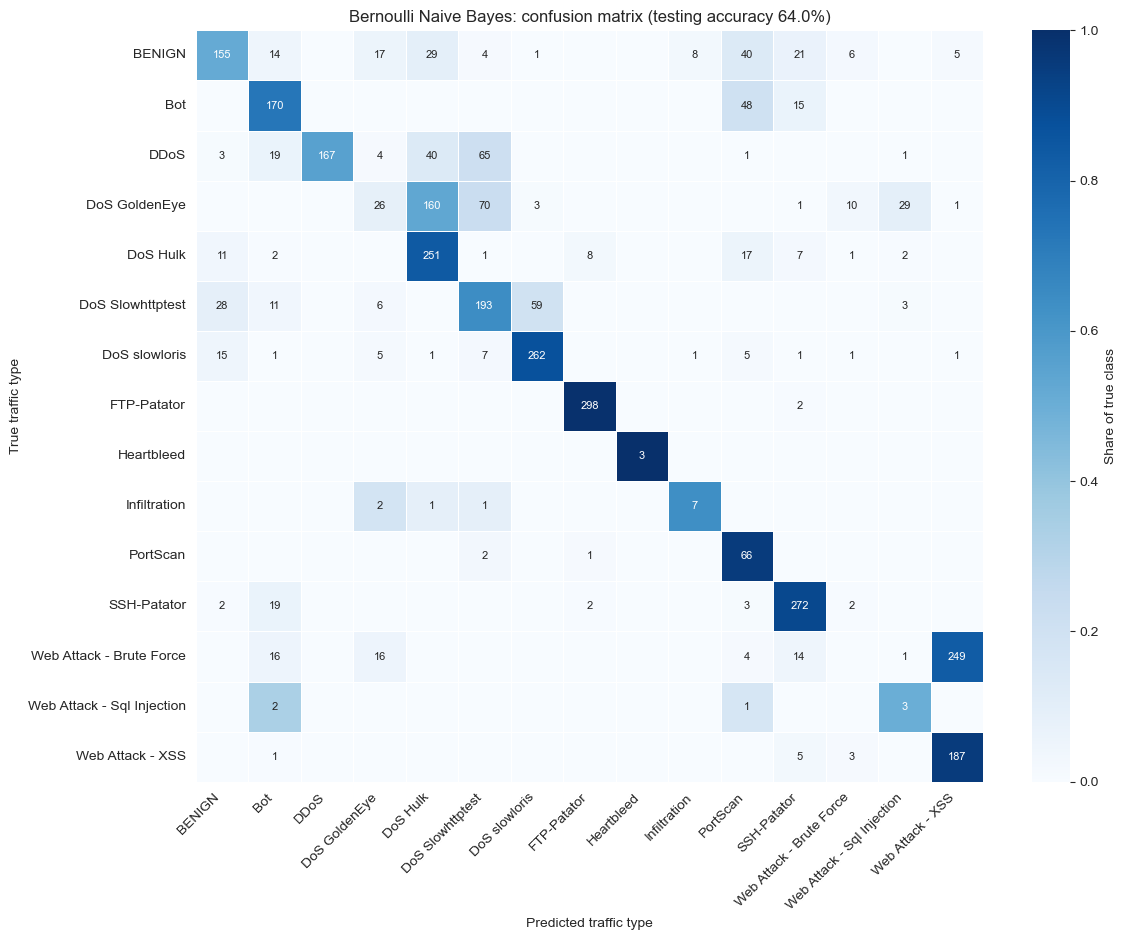

In [13]:
cm_bnb = plot_confusion(y_test, pred_bnb,
                        f"Bernoulli Naive Bayes: confusion matrix (testing accuracy {acc_bnb:.1%})",
                        "figures/nb-03-confusion-bernoulli.png")

## 6. Comparison of the Models

In [14]:
def alert_rates(y_true, y_pred):
    # False alarm rate: share of BENIGN flows predicted as any attack type
    # Detection rate: share of attack flows predicted as any attack type
    benign = (y_true == "BENIGN").values
    flagged = (y_pred != "BENIGN")
    return flagged[benign].mean(), flagged[~benign].mean()

rows = []
for name, pred in [("Multinomial NB", pred_mnb), ("Bernoulli NB", pred_bnb)]:
    fa, det = alert_rates(y_test, np.asarray(pred))
    rows.append({"Model": name,
                 "Testing accuracy": accuracy_score(y_test, pred),
                 "Macro recall": classification_report(y_test, pred, output_dict=True, zero_division=0)["macro avg"]["recall"],
                 "False alarm rate": fa, "Detection rate": det})

comparison = pd.DataFrame(rows).set_index("Model")
comparison.loc["Majority-class baseline"] = [baseline_acc, 1 / len(classes), np.nan, np.nan]
comparison.round(3)

,Testing accuracy,Macro recall,False alarm rate,Detection rate
Model,,,,
Multinomial NB,0.564,0.583,0.393,0.952
Bernoulli NB,0.640,0.679,0.483,0.980
Majority-class baseline,0.093,0.067,NaN,NaN


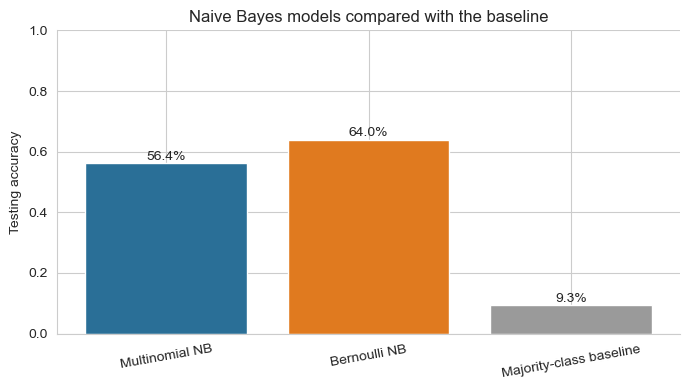

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
vals = comparison["Testing accuracy"]
bars = ax.bar(vals.index, vals.values, color=["#2a6f97", "#e07a1f", "#9a9a9a"])
for b, v in zip(bars, vals.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center", fontsize=10)
ax.set_ylim(0, 1)
ax.set_ylabel("Testing accuracy")
ax.set_title("Naive Bayes models compared with the baseline")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("figures/nb-04-model-comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Posterior Probabilities for One Flow

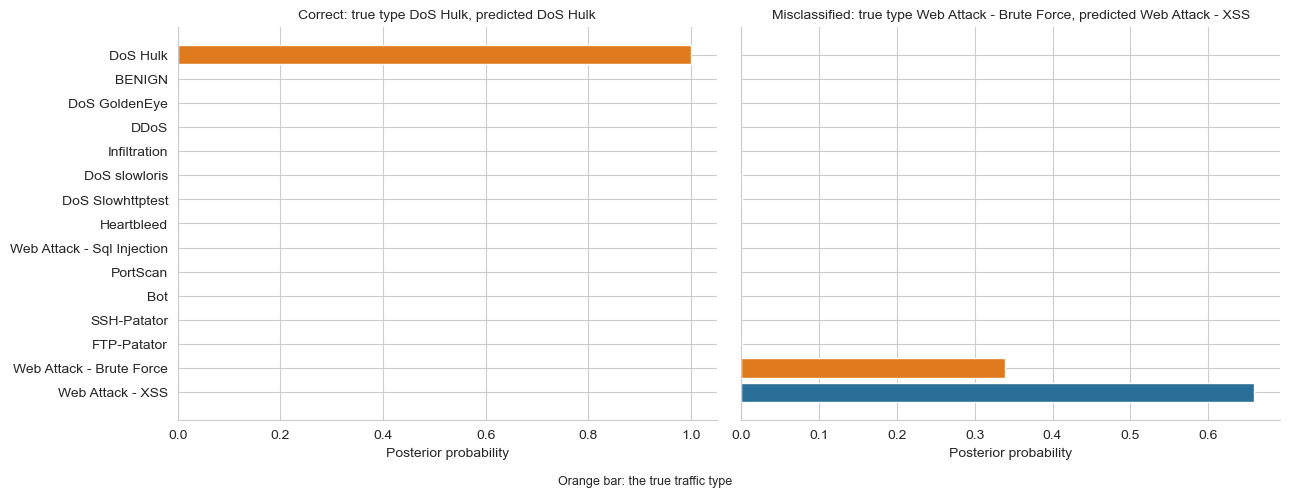

In [16]:
proba = mnb.predict_proba(S_test)
correct = np.where(pred_mnb == y_test.values)[0]
wrong = np.where(pred_mnb != y_test.values)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, idx, tag in [(axes[0], correct[0], "Correct"), (axes[1], wrong[0], "Misclassified")]:
    p = pd.Series(proba[idx], index=mnb.classes_).sort_values()
    colors = ["#e07a1f" if c == y_test.iloc[idx] else "#2a6f97" for c in p.index]
    ax.barh(p.index, p.values, color=colors)
    ax.set_title(f"{tag}: true type {y_test.iloc[idx]}, predicted {pred_mnb[idx]}", fontsize=10)
    ax.set_xlabel("Posterior probability")
axes[0].set_ylabel("")
fig.text(0.5, -0.02, "Orange bar: the true traffic type", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("figures/nb-05-posterior-example.png", dpi=160, bbox_inches="tight")
plt.show()